# Awake vs. isoflurane, clustered separately — GMM, mouse 709401

The recording is split into its two labelled states, and a Gaussian mixture model (K = 5) is fit to each state **on its own**:

- **Signals:** LFP probeF MOs5 and EEG ch 13 (MOs), 6 band envelopes, 1 sample per second.
- **States:** the trial-labelled epochs — awake ≈ 758–3069 s, isoflurane ≈ 4768–7080 s (induction is left out).
- **Z-scoring:** within each state, so each state's clusters describe structure *inside* that state.
- **Matching colors:** awake and isoflurane clusters are paired by how similar their centers are (cosine similarity, best one-to-one pairing). Pairs above `SIMILAR` get the **same color** and the name *Shared n*; clusters without a match are *Awake-only* or *Iso-only*.

Colors are matched within each signal (LFP awake ↔ LFP iso, EEG awake ↔ EEG iso), not between LFP and EEG.

In [1]:
import os, sys, glob, types
os.chdir(os.path.expanduser("~/dc-allen-data-acquire/code/python/notebooks"))
sys.path.append("..")
src_dir = os.path.abspath("../src")
mapping = types.ModuleType("src.mapping")
mapping.__path__ = [src_dir]
sys.modules["src.mapping"] = mapping
print("Now in:", os.getcwd())

Now in: /Users/jahansheikh/dc-allen-data-acquire/code/python/notebooks


In [2]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO
from scipy import signal
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture

from src.mapping.lfp_to_motifs import prepare
from src.mapping.smooth_env import smooth_env, mround, DEFAULT_FREQ_BANDS
%matplotlib inline

DATA_DIR = os.path.expanduser("~/dc-allen-data-acquire/data/raw/")
PATH = glob.glob(os.path.join(DATA_DIR, "*709401*.nwb"))[0]
io = NWBHDF5IO(PATH, mode="r")
nwb = io.read()

OUT = Path("results/709401_jahan/awake_vs_iso_gmm")
OUT.mkdir(parents=True, exist_ok=True)

trials = nwb.trials.to_dataframe()
STATES = sorted([(str(k), float(g.start_time.min()), float(g.stop_time.max()))
                 for k, g in trials.groupby("behavioral_epoch")], key=lambda s: s[1])
print("File:", os.path.basename(PATH))
print("Labelled states:", [(n, round(a), round(b)) for n, a, b in STATES])

File: 709401-20231213-v001.nwb
Labelled states: [('awake', 758, 3069), ('isoflurane', 4768, 7080)]


## Settings

In [3]:
K = 5                                   # clusters per state
STATE_NAMES = ["awake", "isoflurane"]
SIMILAR = 0.7                           # cosine similarity needed to call two clusters the same motif
N_SEEDS = 5                             # for the seed-stability check
BAND_LABELS = [f"{lo:g}-{hi:g}" for lo, hi in DEFAULT_FREQ_BANDS]
PALETTE = [matplotlib.colormaps["tab10"](i) for i in range(10)]

## Load band envelopes (1 per second)

Same preprocessing as the main notebook: LFP through the team's `prepare`, EEG with a 60 Hz notch, then `smooth_env`. Loading takes a few minutes.

In [4]:
def lfp_envelopes(probe="probeF", region="MOs5", target_fs=250.0):
    prep = prepare([PATH], probe, region, target_fs, DEFAULT_FREQ_BANDS)
    return prep["envelopes"][0], prep["sessions"][0]["t"], prep["fs"]

def eeg_envelopes(ch, target_fs=250.0):
    s = nwb.acquisition["ElectricalSeriesEEG"]
    ts = s.timestamps[:]
    fs_raw = 1 / np.median(np.diff(ts[:100_000]))
    raw = s.data[:, ch] * s.conversion * 1e6            # microvolts
    b, a = signal.iirnotch(60, 30, fs_raw)               # 60 Hz line noise
    raw = signal.filtfilt(b, a, raw)
    q = mround(fs_raw / target_fs)
    x, t, fs = signal.decimate(raw, q, zero_phase=True), ts[::q], fs_raw / q
    env = smooth_env(x, fs, DEFAULT_FREQ_BANDS)
    ok = np.isfinite(env).all(axis=1)
    return env[ok], t[ok], fs

signals = {}
for name, loader in [("LFP MOs5", lfp_envelopes), ("EEG ch 13 (MOs)", lambda: eeg_envelopes(13))]:
    env, t, fs = loader()
    hop = mround(fs)
    signals[name] = {"env": env[::hop], "t": t[::hop]}
    print(f"{name}: {len(signals[name]['t'])} seconds")

[prep] 709401-20231213-v001.nwb: isoflurane, probeF MOs5 channel 304, 7306 s at 250.0 Hz (4s)
LFP MOs5: 7307 seconds
EEG ch 13 (MOs): 7307 seconds


## Split, z-score within each state, fit the GMMs

In [5]:
def split_state(sig, state):
    """Seconds inside one labelled state, z-scored with that state's own mean and SD."""
    _, a, b = next(s for s in STATES if s[0] == state)
    keep = (sig["t"] >= a) & (sig["t"] <= b)
    x = sig["env"][keep]
    return {"X": (x - x.mean(axis=0)) / x.std(axis=0), "t": sig["t"][keep]}

def fit(X, k, seed=0, n_init=5):
    return GaussianMixture(k, covariance_type="full", n_init=n_init, random_state=seed).fit(X)

fits = {}
for name, sig in signals.items():
    for state in STATE_NAMES:
        d = split_state(sig, state)
        g = fit(d["X"], K)
        d["labels"] = g.predict(d["X"])
        d["centers"] = g.means_
        d["occupancy"] = np.bincount(d["labels"], minlength=K) / len(d["labels"])
        d["bic"] = [fit(d["X"], k, n_init=2).bic(d["X"]) for k in range(1, 11)]
        seed_labels = [fit(d["X"], K, seed=s, n_init=1).predict(d["X"]) for s in range(N_SEEDS)]
        d["stability"] = np.mean([adjusted_rand_score(a, b) for a, b in combinations(seed_labels, 2)])
        fits[(name, state)] = d
        print(f"{name:16s} {state:10s}: {len(d['t'])} s, seed stability (ARI) {d['stability']:.2f}")

LFP MOs5         awake     : 2311 s, seed stability (ARI) 0.94
LFP MOs5         isoflurane: 2312 s, seed stability (ARI) 0.81
EEG ch 13 (MOs)  awake     : 2311 s, seed stability (ARI) 0.85
EEG ch 13 (MOs)  isoflurane: 2312 s, seed stability (ARI) 0.88


## Match clusters between awake and isoflurane (same color = similar motif)

Each awake cluster center is compared with each isoflurane cluster center using cosine similarity (1 = same direction, 0 = unrelated, −1 = opposite). The best one-to-one pairing is found with the Hungarian algorithm; pairs at or above `SIMILAR` are called *Shared* and share a color.

In [6]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

def slow_minus_fast(c):
    return c[:4].mean() - c[4:].mean()

def match_states(name):
    ca, ci = fits[(name, "awake")]["centers"], fits[(name, "isoflurane")]["centers"]
    S = np.array([[cosine(a, b) for b in ci] for a in ca])
    rows, cols = linear_sum_assignment(-S)
    pairs = [(r, c) for r, c in zip(rows, cols) if S[r, c] >= SIMILAR]
    pairs.sort(key=lambda p: -slow_minus_fast(ca[p[0]]))          # slow-dominant first

    style = {"awake": {}, "isoflurane": {}}                          # cluster -> (name, color)
    k = 0
    for j, (a, i) in enumerate(pairs):
        style["awake"][a] = style["isoflurane"][i] = (f"Shared {j + 1}", PALETTE[k])
        k += 1
    for state, centers, tag in [("awake", ca, "Awake-only"), ("isoflurane", ci, "Iso-only")]:
        rest = sorted(set(range(K)) - set(style[state]), key=lambda c: -slow_minus_fast(centers[c]))
        for j, c in enumerate(rest):
            style[state][c] = (f"{tag} {chr(65 + j)}", PALETTE[k])
            k += 1
    return S, pairs, style

matches = {name: match_states(name) for name in signals}
for name, (S, pairs, style) in matches.items():
    print(f"\n{name}: {len(pairs)} of {K} clusters shared between awake and isoflurane")
    for a, i in pairs:
        print(f"  {style['awake'][a][0]}: awake cluster {a} <-> iso cluster {i}  (cosine {S[a, i]:+.2f})")


LFP MOs5: 4 of 5 clusters shared between awake and isoflurane
  Shared 1: awake cluster 4 <-> iso cluster 2  (cosine +0.97)
  Shared 2: awake cluster 0 <-> iso cluster 0  (cosine +0.99)
  Shared 3: awake cluster 1 <-> iso cluster 4  (cosine +0.94)
  Shared 4: awake cluster 2 <-> iso cluster 3  (cosine +0.80)

EEG ch 13 (MOs): 1 of 5 clusters shared between awake and isoflurane
  Shared 1: awake cluster 2 <-> iso cluster 2  (cosine +0.72)


## Results, back to back

For each signal:
1. **Cluster centers** — awake (left) and isoflurane (right) on the same axes; same color = matched motif.
2. **Similarity matrix** — every awake cluster against every isoflurane cluster; boxed cells are the matched pairs.
3. **Occupancy** — share of each state's seconds in each cluster.
4. **Timelines** — band envelopes (z-scored within the state) with the cluster strip underneath.

In [7]:
def plot_centers(name):
    S, pairs, style = matches[name]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
    for ax, state in zip(axes, STATE_NAMES):
        d = fits[(name, state)]
        order = sorted(range(K), key=lambda c: style[state][c][0])
        for c in order:
            label, color = style[state][c]
            ls = "-" if label.startswith("Shared") else "--"
            ax.plot(BAND_LABELS, d["centers"][c], ls, marker="o", color=color, lw=2,
                    label=f"{label} ({d['occupancy'][c]:.0%})")
        ax.axhline(0, color="0.7", lw=0.8)
        ax.set(title=f"{state}  ({len(d['t'])} s, seed stability {d['stability']:.2f})", xlabel="Band (Hz)")
        ax.tick_params(axis="x", rotation=45)
        ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
    axes[0].set_ylabel("Cluster center (z, within state)")
    fig.suptitle(f"{name}: GMM cluster centers, K = {K}, fit separately per state — mouse 709401\n"
                 "same color = matched motif (solid); dashed = found in only one state", fontsize=10)
    plt.tight_layout()
    plt.savefig(OUT / f"{name.split(' (')[0].replace(' ', '_')}_centers.png", dpi=150, bbox_inches="tight")
    plt.show()

def plot_similarity(name):
    S, pairs, style = matches[name]
    fig, ax = plt.subplots(figsize=(6.4, 5))
    im = ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
    for (a, i), v in np.ndenumerate(S):
        ax.text(i, a, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
    for a, i in pairs:
        ax.add_patch(plt.Rectangle((i - 0.5, a - 0.5), 1, 1, fill=False, ec="k", lw=2.5))
    ax.set_yticks(range(K), [style["awake"][c][0] for c in range(K)], fontsize=8)
    ax.set_xticks(range(K), [style["isoflurane"][c][0] for c in range(K)], fontsize=8, rotation=35, ha="right")
    for tick, c in zip(ax.get_yticklabels(), range(K)):
        tick.set_color(style["awake"][c][1])
    for tick, c in zip(ax.get_xticklabels(), range(K)):
        tick.set_color(style["isoflurane"][c][1])
    ax.set(ylabel="Awake clusters", xlabel="Isoflurane clusters")
    fig.colorbar(im, ax=ax, label="Cosine similarity of centers", shrink=0.8)
    ax.set_title(f"{name}: awake vs isoflurane cluster similarity\n(boxed = matched, threshold {SIMILAR})",
                 fontsize=10)
    plt.tight_layout()
    plt.savefig(OUT / f"{name.split(' (')[0].replace(' ', '_')}_similarity.png", dpi=150)
    plt.show()

def plot_occupancy(name):
    S, pairs, style = matches[name]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for x, state in enumerate(STATE_NAMES):
        d = fits[(name, state)]
        bottom = 0.0
        for c in sorted(range(K), key=lambda c: style[state][c][0]):
            label, color = style[state][c]
            ax.bar(x, d["occupancy"][c], bottom=bottom, color=color, edgecolor="white",
                   hatch=None if label.startswith("Shared") else "//")
            if d["occupancy"][c] > 0.04:
                ax.text(x, bottom + d["occupancy"][c] / 2, f"{label}\n{d['occupancy'][c]:.0%}",
                        ha="center", va="center", fontsize=7)
            bottom += d["occupancy"][c]
    ax.set_xticks(range(len(STATE_NAMES)), STATE_NAMES)
    ax.set(ylabel="Fraction of seconds", ylim=(0, 1))
    ax.set_title(f"{name}: cluster occupancy per state (hatched = only in one state)", fontsize=10)
    plt.tight_layout()
    plt.savefig(OUT / f"{name.split(' (')[0].replace(' ', '_')}_occupancy.png", dpi=150)
    plt.show()

def plot_timelines(name):
    S, pairs, style = matches[name]
    fig, axes = plt.subplots(4, 1, figsize=(14, 6.5), layout="constrained",
                             gridspec_kw={"height_ratios": [3, 0.8, 3, 0.8]})
    for row, state in enumerate(STATE_NAMES):
        d = fits[(name, state)]
        t = d["t"]
        ax = axes[2 * row]
        ax.imshow(d["X"].T, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-2.5, vmax=2.5,
                  extent=[t[0], t[-1], -0.5, len(BAND_LABELS) - 0.5], interpolation="none")
        ax.set_yticks(range(len(BAND_LABELS)), BAND_LABELS, fontsize=7)
        ax.set_ylabel("Band (Hz)")
        ax.set_title(f"{state}: band envelopes (z within state) and GMM clusters", fontsize=9)
        ax.set_xticks([])
        strip = axes[2 * row + 1]
        rgb = np.ones((1, len(t), 3))
        for c in range(K):
            rgb[0, d["labels"] == c] = style[state][c][1][:3]
        strip.imshow(rgb, aspect="auto", extent=[t[0], t[-1], 0, 1], interpolation="none")
        strip.set_yticks([])
        strip.set_xlabel("Session time (s)")
    handles, names = [], []
    for state in STATE_NAMES:
        for c in range(K):
            label, color = style[state][c]
            if label not in names:
                names.append(label)
                handles.append(plt.Rectangle((0, 0), 1, 1, color=color))
    fig.legend(handles, names, loc="outside lower center", ncol=min(len(names), 6), fontsize=8)
    fig.suptitle(f"{name}: awake and isoflurane clustered separately (K = {K}) — mouse 709401", fontsize=10)
    plt.savefig(OUT / f"{name.split(' (')[0].replace(' ', '_')}_timelines.png", dpi=150)
    plt.show()

def cluster_table(name):
    S, pairs, style = matches[name]
    partner = {("awake", a): (i, S[a, i]) for a, i in pairs}
    partner.update({("isoflurane", i): (a, S[a, i]) for a, i in pairs})
    rows = []
    for state in STATE_NAMES:
        d = fits[(name, state)]
        for c in range(K):
            p = partner.get((state, c))
            rows.append({"state": state, "cluster": c, "name": style[state][c][0],
                         "% of state": round(100 * d["occupancy"][c], 1),
                         "matched cosine": None if p is None else round(p[1], 2),
                         **{b: round(v, 2) for b, v in zip(BAND_LABELS, d["centers"][c])}})
    return pd.DataFrame(rows).sort_values(["name", "state"]).set_index(["name", "state"])

def show_signal(name):
    plot_centers(name)
    plot_similarity(name)
    plot_occupancy(name)
    plot_timelines(name)
    table = cluster_table(name)
    table.to_csv(OUT / f"{name.split(' (')[0].replace(' ', '_')}_clusters.csv")
    print(table.to_string())

### LFP MOs5

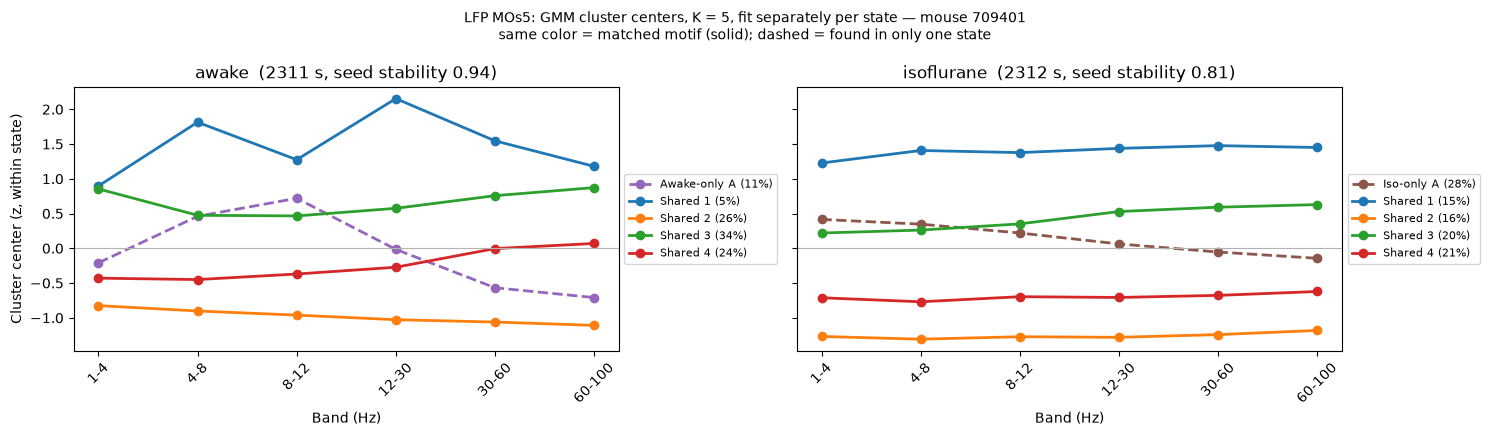

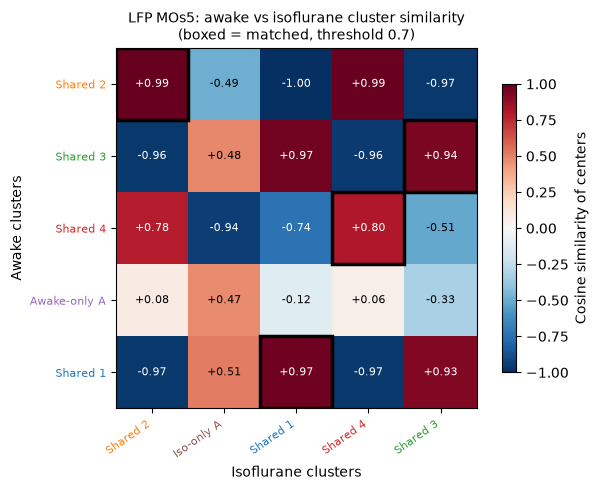

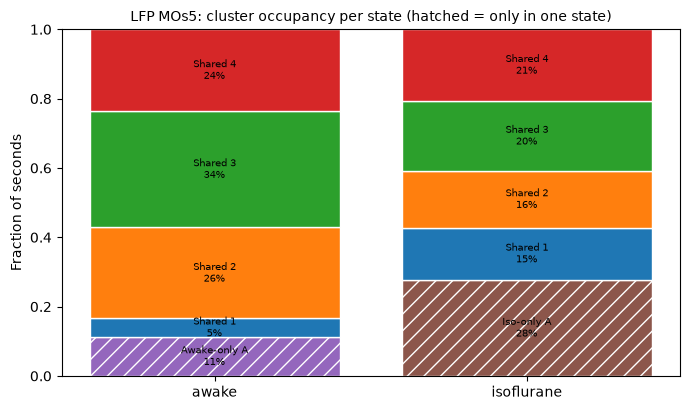

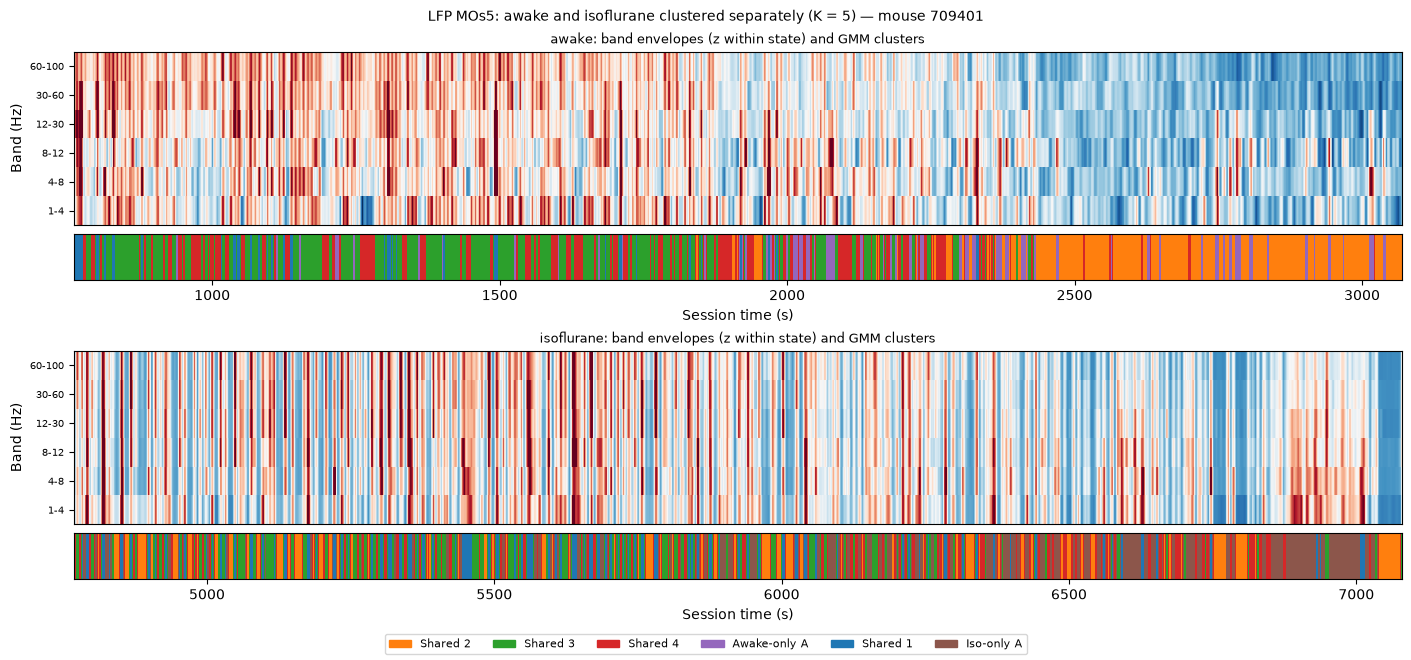

                         cluster  % of state  matched cosine   1-4   4-8  8-12  12-30  30-60  60-100
name         state                                                                                  
Awake-only A awake             3        11.3             NaN -0.21  0.46  0.72  -0.02  -0.57   -0.71
Iso-only A   isoflurane        1        27.7             NaN  0.42  0.35  0.22   0.06  -0.05   -0.14
Shared 1     awake             4         5.2            0.97  0.90  1.81  1.27   2.15   1.55    1.18
             isoflurane        2        15.1            0.97  1.23  1.41  1.38   1.44   1.48    1.45
Shared 2     awake             0        26.3            0.99 -0.82 -0.90 -0.96  -1.03  -1.06   -1.11
             isoflurane        0        16.3            0.99 -1.27 -1.31 -1.27  -1.28  -1.24   -1.18
Shared 3     awake             1        33.6            0.94  0.85  0.47  0.47   0.58   0.76    0.87
             isoflurane        4        20.3            0.94  0.22  0.26  0.35   0.53   0.5

In [8]:
show_signal("LFP MOs5")

### EEG ch 13 (MOs)

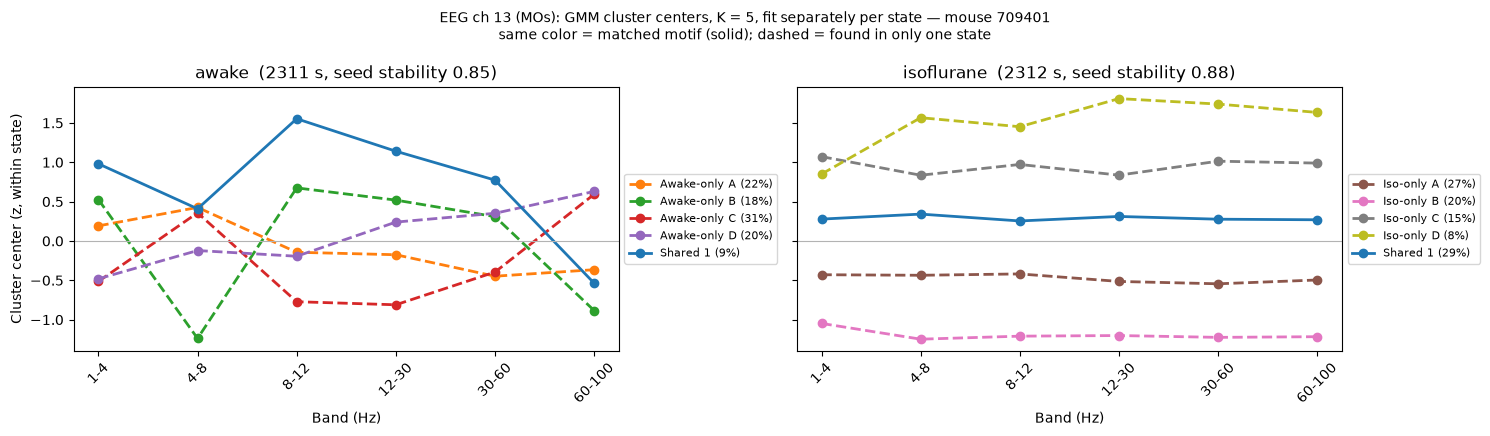

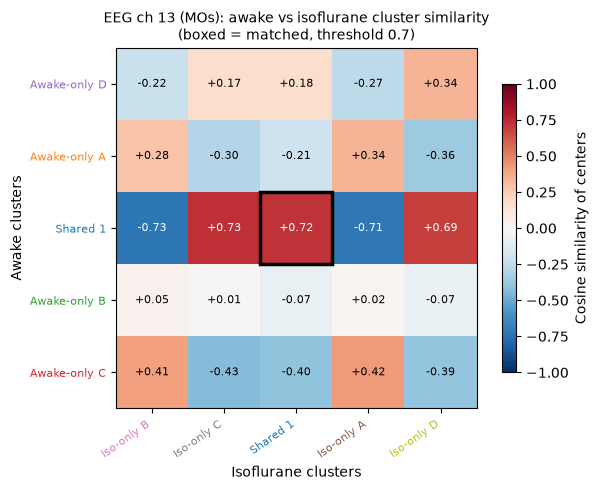

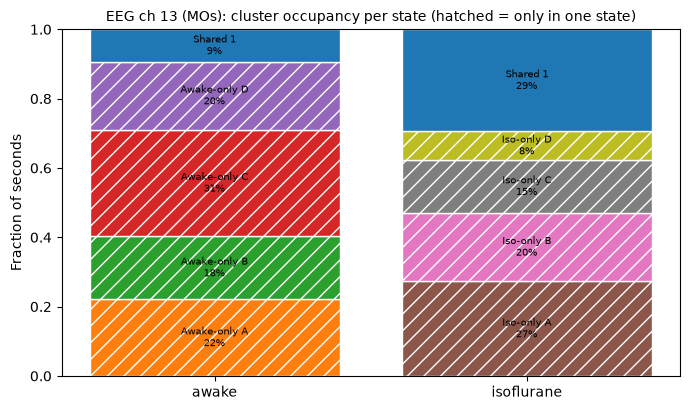

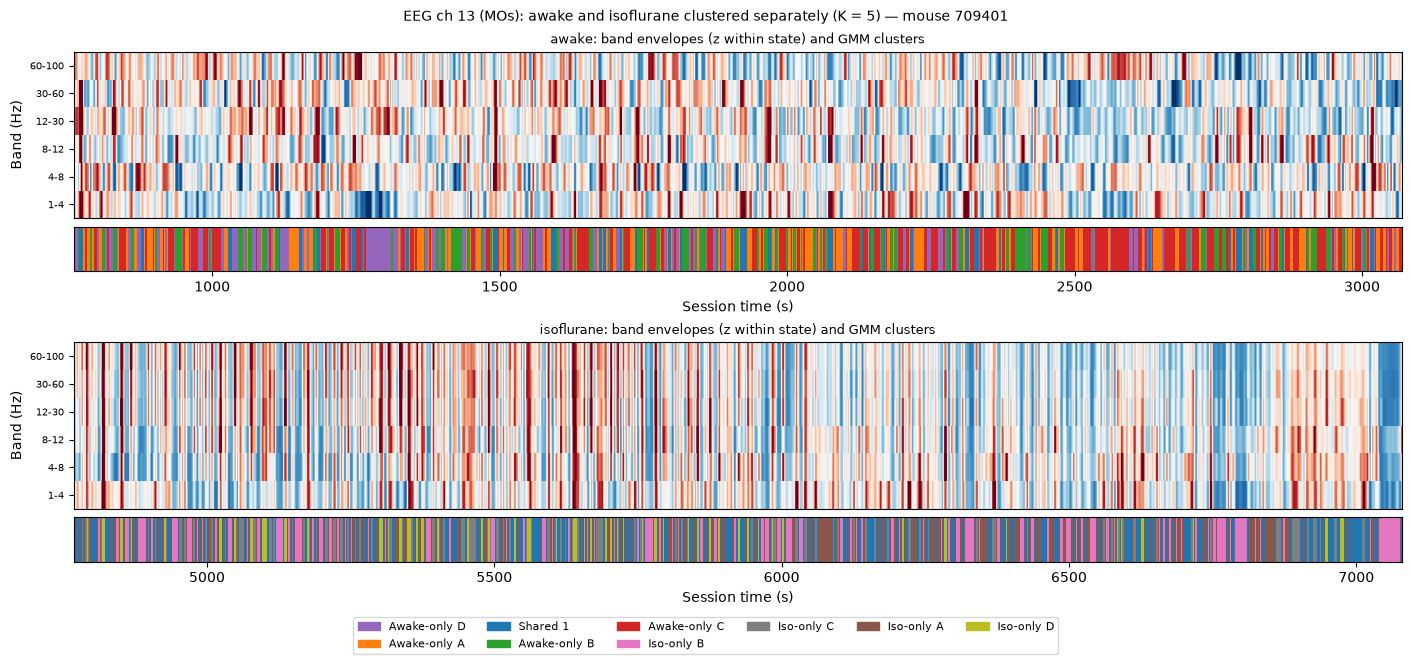

                         cluster  % of state  matched cosine   1-4   4-8  8-12  12-30  30-60  60-100
name         state                                                                                  
Awake-only A awake             1        22.2             NaN  0.19  0.43 -0.14  -0.17  -0.45   -0.36
Awake-only B awake             3        18.1             NaN  0.53 -1.24  0.67   0.52   0.31   -0.88
Awake-only C awake             4        30.8             NaN -0.51  0.36 -0.77  -0.81  -0.39    0.59
Awake-only D awake             0        19.6             NaN -0.48 -0.12 -0.19   0.24   0.35    0.63
Iso-only A   isoflurane        3        27.3             NaN -0.43 -0.44 -0.42  -0.51  -0.54   -0.50
Iso-only B   isoflurane        0        19.8             NaN -1.05 -1.25 -1.21  -1.20  -1.22   -1.22
Iso-only C   isoflurane        1        15.2             NaN  1.07  0.84  0.97   0.84   1.01    0.99
Iso-only D   isoflurane        4         8.3             NaN  0.85  1.57  1.45   1.81   1.7

In [9]:
show_signal("EEG ch 13 (MOs)")

## How many clusters does each state support? (BIC, lower = better)

K = 5 is used everywhere above so the states are easy to compare; this shows whether either state would prefer a different K.

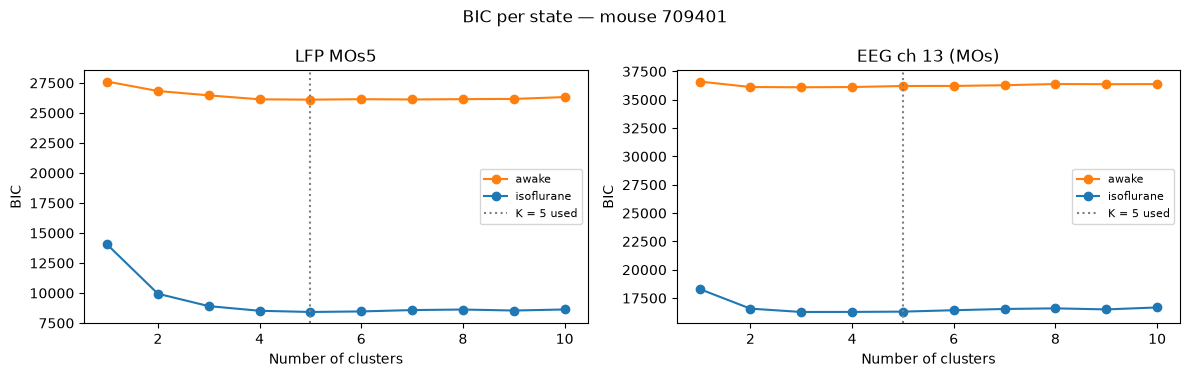

In [10]:
fig, axes = plt.subplots(1, len(signals), figsize=(6 * len(signals), 3.8), squeeze=False)
for ax, name in zip(axes[0], signals):
    for state, color in zip(STATE_NAMES, ["C1", "C0"]):
        ax.plot(range(1, 11), fits[(name, state)]["bic"], "-o", color=color, label=state)
    ax.axvline(K, color="0.5", ls=":", label=f"K = {K} used")
    ax.set(title=name, xlabel="Number of clusters", ylabel="BIC")
    ax.legend(fontsize=8)
fig.suptitle("BIC per state — mouse 709401")
plt.tight_layout()
plt.savefig(OUT / "bic_per_state.png", dpi=150)
plt.show()


LFP MOs5: 8 awake–isoflurane links with cosine >= 0.7
  Shared 1·a   (awake 0) <-> Shared 1·a   (iso 0)  cosine +0.99
  Shared 1·a   (awake 0) <-> Shared 1·b   (iso 3)  cosine +0.99
  Shared 1·b   (awake 2) <-> Shared 1·a   (iso 0)  cosine +0.78
  Shared 1·b   (awake 2) <-> Shared 1·b   (iso 3)  cosine +0.80
  Shared 2·a   (awake 4) <-> Shared 2·a   (iso 2)  cosine +0.97
  Shared 2·a   (awake 4) <-> Shared 2·b   (iso 4)  cosine +0.93
  Shared 2·b   (awake 1) <-> Shared 2·a   (iso 2)  cosine +0.97
  Shared 2·b   (awake 1) <-> Shared 2·b   (iso 4)  cosine +0.94

EEG ch 13 (MOs): 2 awake–isoflurane links with cosine >= 0.7
  Shared 1     (awake 2) <-> Shared 1·b   (iso 1)  cosine +0.73
  Shared 1     (awake 2) <-> Shared 1·a   (iso 2)  cosine +0.72

######## LFP MOs5 ########


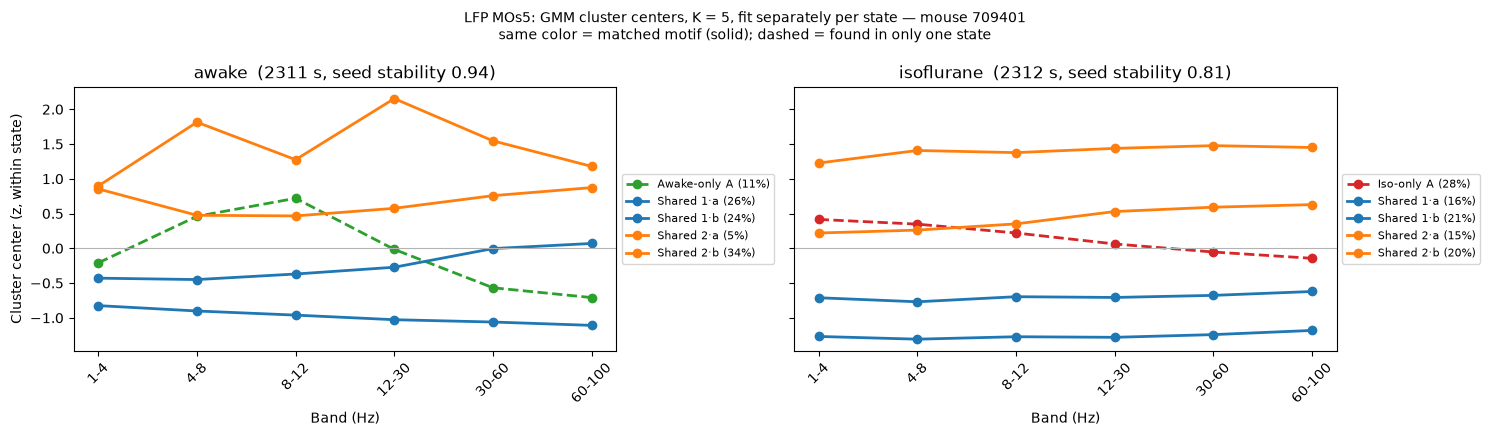

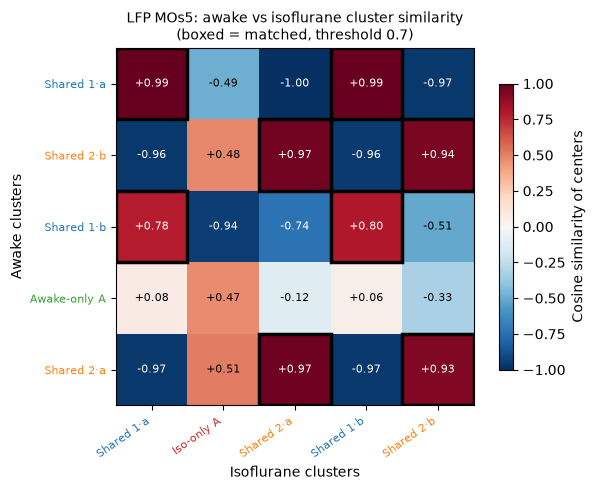

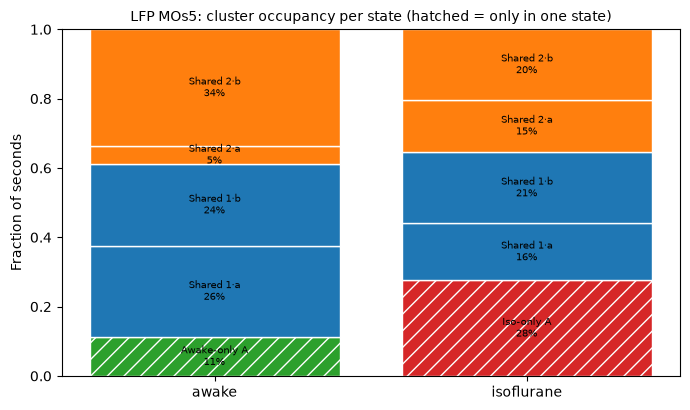

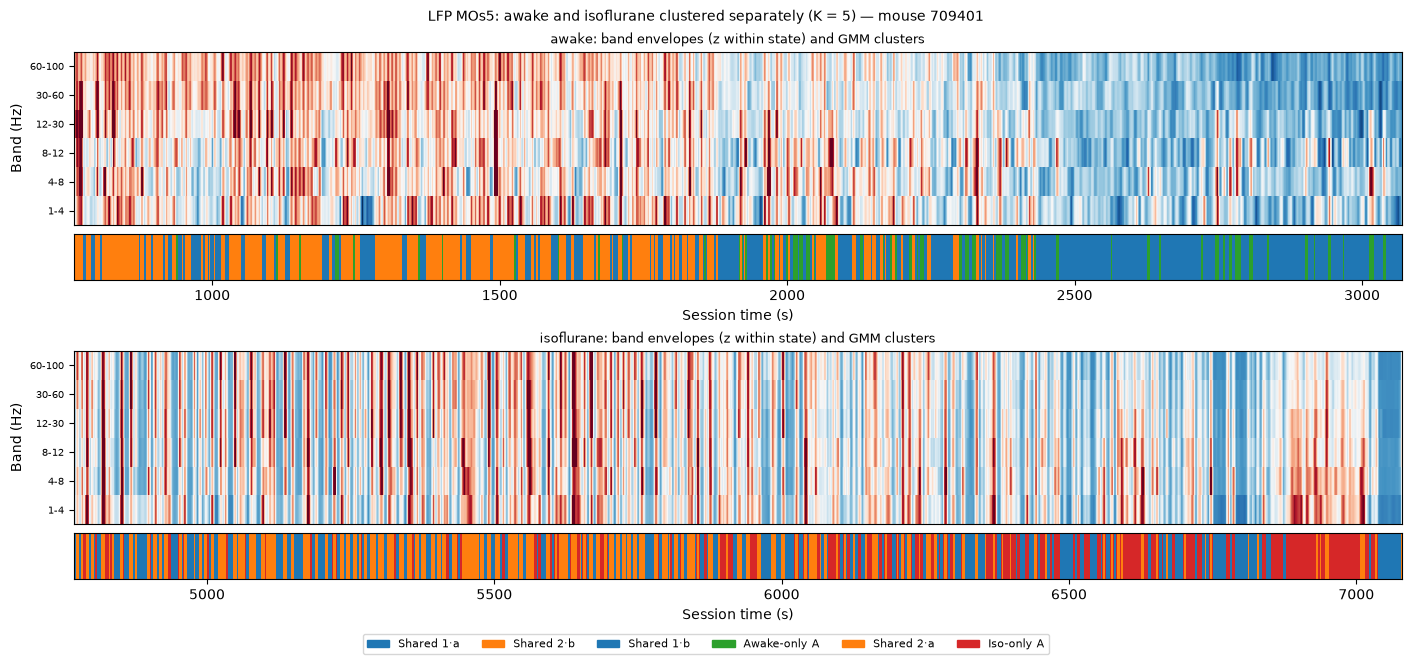

                         cluster  % of state               linked to  best link cosine   1-4   4-8  8-12  12-30  30-60  60-100
name         state                                                                                                            
Awake-only A awake             3        11.3                       -               NaN -0.21  0.46  0.72  -0.02  -0.57   -0.71
Iso-only A   isoflurane        1        27.7                       -               NaN  0.42  0.35  0.22   0.06  -0.05   -0.14
Shared 1·a   awake             0        26.3  Shared 1·a, Shared 1·b              0.99 -0.82 -0.90 -0.96  -1.03  -1.06   -1.11
             isoflurane        0        16.3  Shared 1·a, Shared 1·b              0.99 -1.27 -1.31 -1.27  -1.28  -1.24   -1.18
Shared 1·b   awake             2        23.6  Shared 1·a, Shared 1·b              0.80 -0.43 -0.45 -0.37  -0.27  -0.00    0.07
             isoflurane        3        20.6  Shared 1·a, Shared 1·b              0.99 -0.71 -0.77 -0.70  -0.71

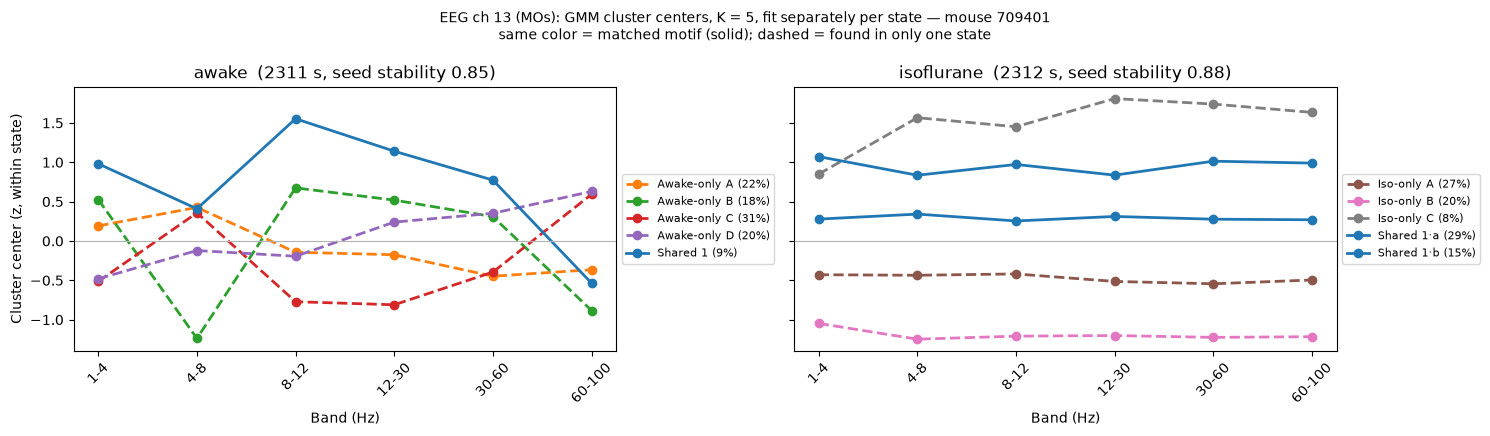

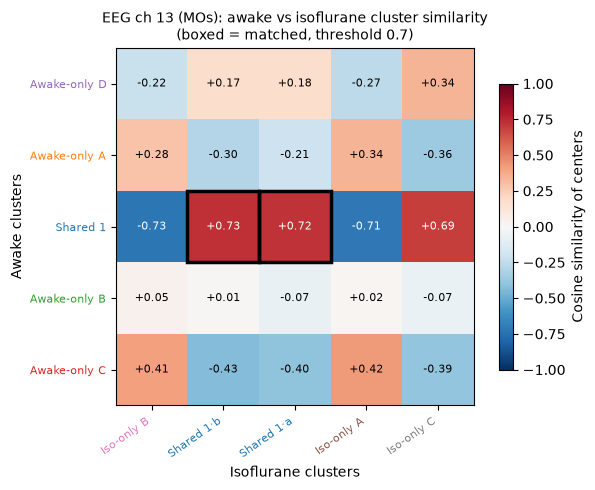

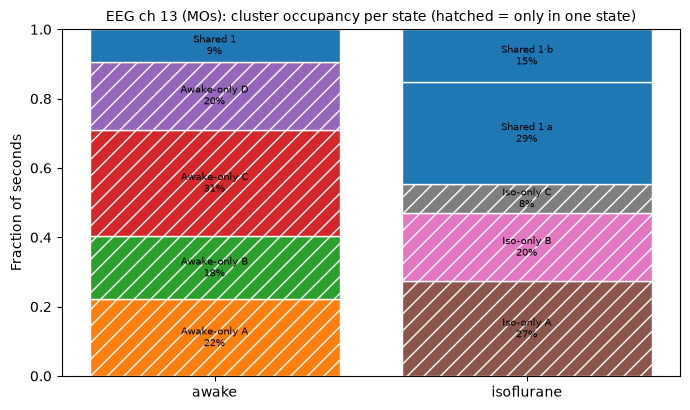

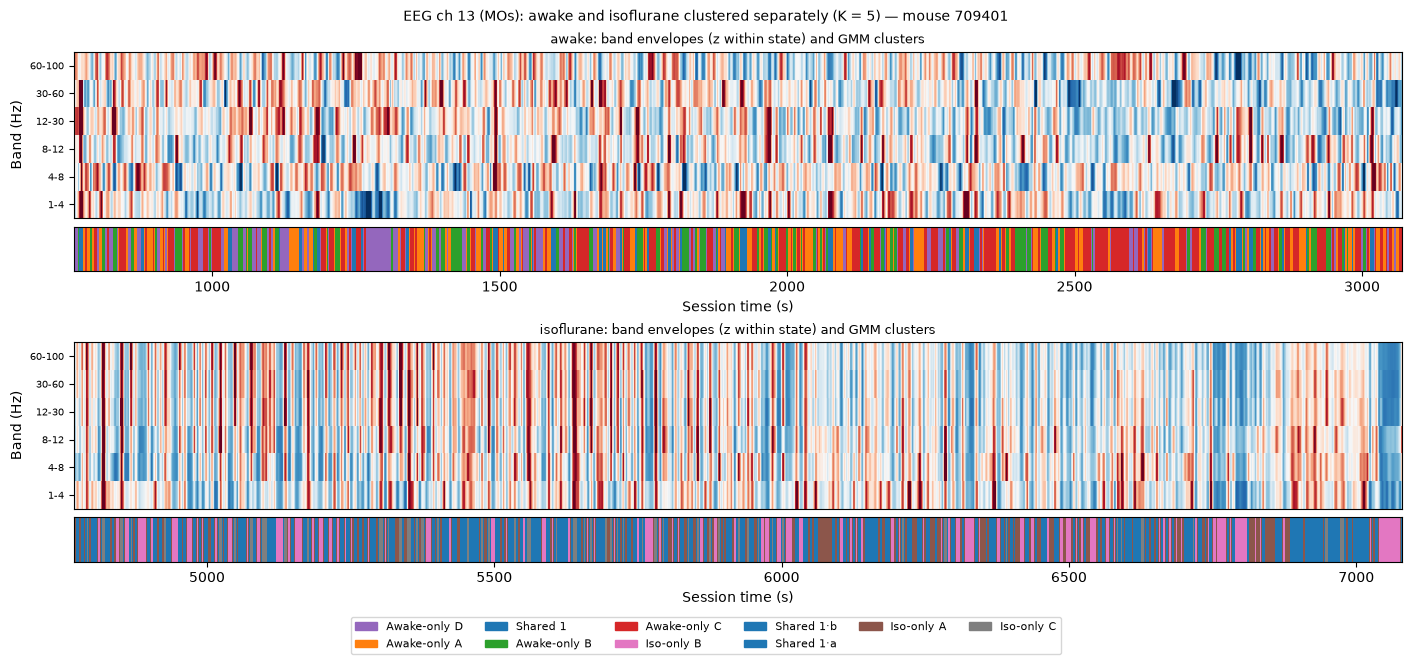

                         cluster  % of state               linked to  best link cosine   1-4   4-8  8-12  12-30  30-60  60-100
name         state                                                                                                            
Awake-only A awake             1        22.2                       -               NaN  0.19  0.43 -0.14  -0.17  -0.45   -0.36
Awake-only B awake             3        18.1                       -               NaN  0.53 -1.24  0.67   0.52   0.31   -0.88
Awake-only C awake             4        30.8                       -               NaN -0.51  0.36 -0.77  -0.81  -0.39    0.59
Awake-only D awake             0        19.6                       -               NaN -0.48 -0.12 -0.19   0.24   0.35    0.63
Iso-only A   isoflurane        3        27.3                       -               NaN -0.43 -0.44 -0.42  -0.51  -0.54   -0.50
Iso-only B   isoflurane        0        19.8                       -               NaN -1.05 -1.25 -1.21  -1.20

In [11]:
# === Match clusters as FAMILIES (one cluster can link to several in the other state) ===
# Every awake–isoflurane pair with cosine similarity >= SIMILAR is linked. Clusters connected
# through links form one family and share one color. Names: "Shared n" (with ·a, ·b when a
# state has several clusters in the same family); unlinked clusters stay "Awake-only"/"Iso-only".
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

MATCHING = "families"          # "families" or "one-to-one" (the original pairing)

def match_families(name):
    ca, ci = fits[(name, "awake")]["centers"], fits[(name, "isoflurane")]["centers"]
    S = np.array([[cosine(a, b) for b in ci] for a in ca])
    links = [(a, i) for a in range(K) for i in range(K) if S[a, i] >= SIMILAR]

    # graph: awake clusters are nodes 0..K-1, isoflurane clusters are nodes K..2K-1
    A = np.zeros((2 * K, 2 * K), dtype=bool)
    for a, i in links:
        A[a, K + i] = A[K + i, a] = True
    n_comp, comp = connected_components(csr_matrix(A), directed=False)
    families = [np.flatnonzero(comp == f) for f in range(n_comp)]
    families = [f for f in families if (f < K).any() and (f >= K).any()]   # must span both states

    def center(node):
        return ca[node] if node < K else ci[node - K]
    families.sort(key=lambda f: -np.mean([slow_minus_fast(center(n)) for n in f]))   # slow-dominant first

    style = {"awake": {}, "isoflurane": {}}
    k = 0
    for j, fam in enumerate(families):
        color = PALETTE[k % len(PALETTE)]
        k += 1
        for state, centers, members in [("awake", ca, [n for n in fam if n < K]),
                                        ("isoflurane", ci, [n - K for n in fam if n >= K])]:
            members = sorted(members, key=lambda c: -slow_minus_fast(centers[c]))
            for m, c in enumerate(members):
                suffix = f"·{chr(97 + m)}" if len(members) > 1 else ""
                style[state][c] = (f"Shared {j + 1}{suffix}", color)
    for state, centers, tag in [("awake", ca, "Awake-only"), ("isoflurane", ci, "Iso-only")]:
        rest = sorted(set(range(K)) - set(style[state]), key=lambda c: -slow_minus_fast(centers[c]))
        for j, c in enumerate(rest):
            style[state][c] = (f"{tag} {chr(65 + j)}", PALETTE[k % len(PALETTE)])
            k += 1
    return S, links, style

def cluster_table(name):
    """Same table as before, but lists every link a cluster has."""
    S, links, style = matches[name]
    rows = []
    for state in STATE_NAMES:
        d = fits[(name, state)]
        other = "isoflurane" if state == "awake" else "awake"
        for c in range(K):
            if state == "awake":
                partners = [(i, S[c, i]) for a, i in links if a == c]
            else:
                partners = [(a, S[a, c]) for a, i in links if i == c]
            rows.append({"state": state, "cluster": c, "name": style[state][c][0],
                         "% of state": round(100 * d["occupancy"][c], 1),
                         "linked to": ", ".join(style[other][p][0] for p, _ in partners) or "-",
                         "best link cosine": round(max(s for _, s in partners), 2) if partners else None,
                         **{b: round(v, 2) for b, v in zip(BAND_LABELS, d["centers"][c])}})
    return pd.DataFrame(rows).sort_values(["name", "state"]).set_index(["name", "state"])

matches = {name: (match_families(name) if MATCHING == "families" else match_states(name)) for name in signals}

for name, (S, links, style) in matches.items():
    print(f"\n{name}: {len(links)} awake–isoflurane links with cosine >= {SIMILAR}")
    for a, i in sorted(links, key=lambda p: style["awake"][p[0]][0]):
        print(f"  {style['awake'][a][0]:12s} (awake {a}) <-> {style['isoflurane'][i][0]:12s} (iso {i})  cosine {S[a, i]:+.2f}")

for name in signals:
    print(f"\n######## {name} ########")
    show_signal(name)

Seed stability (ARI), K = 5 vs K = 3:
  LFP MOs5         awake     : 0.94 -> 0.92
  LFP MOs5         isoflurane: 0.81 -> 0.98
  EEG ch 13 (MOs)  awake     : 0.85 -> 0.54
  EEG ch 13 (MOs)  isoflurane: 0.88 -> 1.00

Matching: families, threshold 0.7

LFP MOs5: 4 awake–isoflurane links
  Shared 1     (awake 0) <-> Shared 1·a   (iso 0)  cosine +0.99
  Shared 1     (awake 0) <-> Shared 1·b   (iso 2)  cosine +0.99
  Shared 2·a   (awake 1) <-> Shared 2     (iso 1)  cosine +0.74
  Shared 2·b   (awake 2) <-> Shared 2     (iso 1)  cosine +0.99

EEG ch 13 (MOs): 1 awake–isoflurane links
  Shared 1     (awake 0) <-> Shared 1     (iso 1)  cosine +0.83

######## LFP MOs5, K = 3 ########


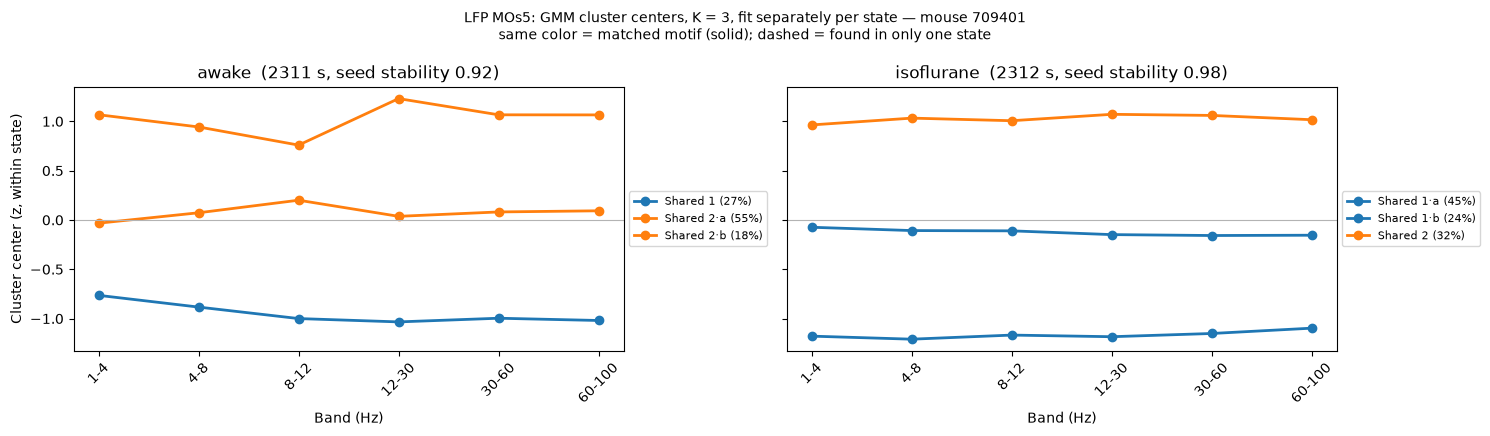

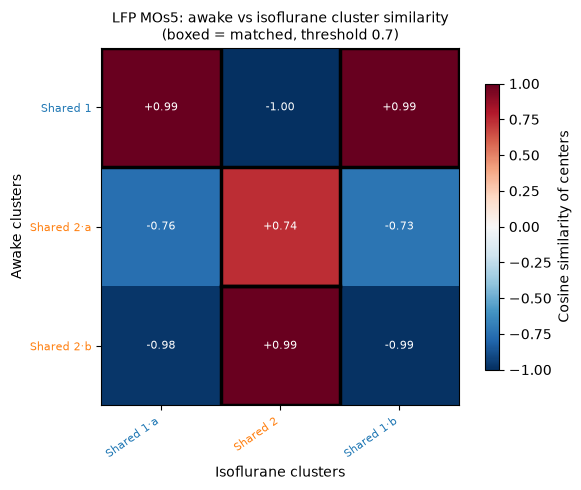

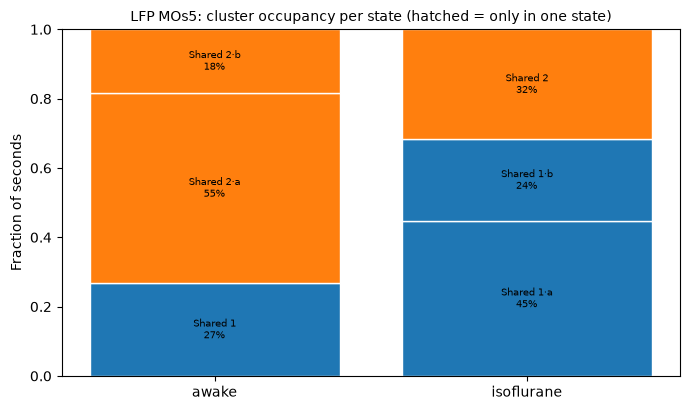

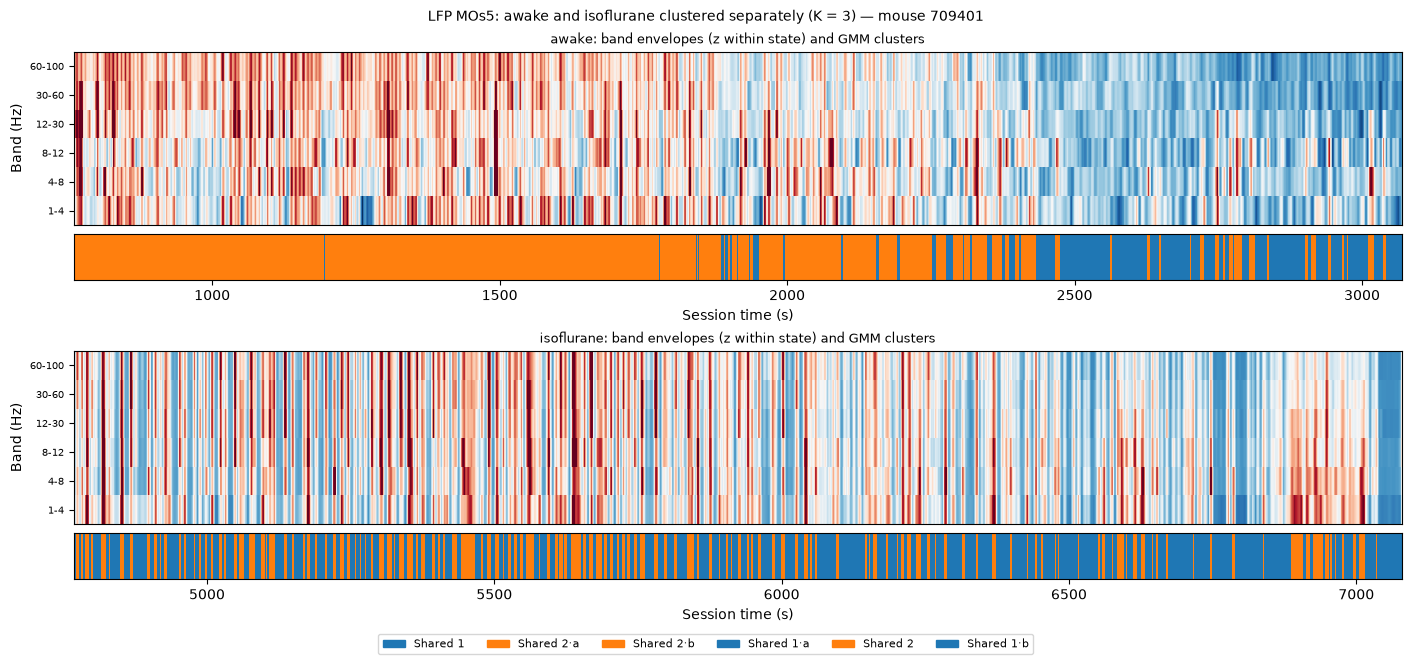

                       cluster  % of state               linked to  best link cosine   1-4   4-8  8-12  12-30  30-60  60-100
name       state                                                                                                            
Shared 1   awake             0        26.7  Shared 1·a, Shared 1·b              0.99 -0.76 -0.88 -1.00  -1.03  -1.00   -1.02
Shared 1·a isoflurane        0        44.7                Shared 1              0.99 -0.07 -0.11 -0.11  -0.15  -0.16   -0.15
Shared 1·b isoflurane        2        23.6                Shared 1              0.99 -1.18 -1.21 -1.17  -1.18  -1.15   -1.10
Shared 2   isoflurane        1        31.7  Shared 2·a, Shared 2·b              0.99  0.96  1.03  1.01   1.07   1.06    1.02
Shared 2·a awake             1        55.0                Shared 2              0.74 -0.03  0.07  0.20   0.04   0.08    0.09
Shared 2·b awake             2        18.3                Shared 2              0.99  1.07  0.94  0.76   1.23   1.07    1.07


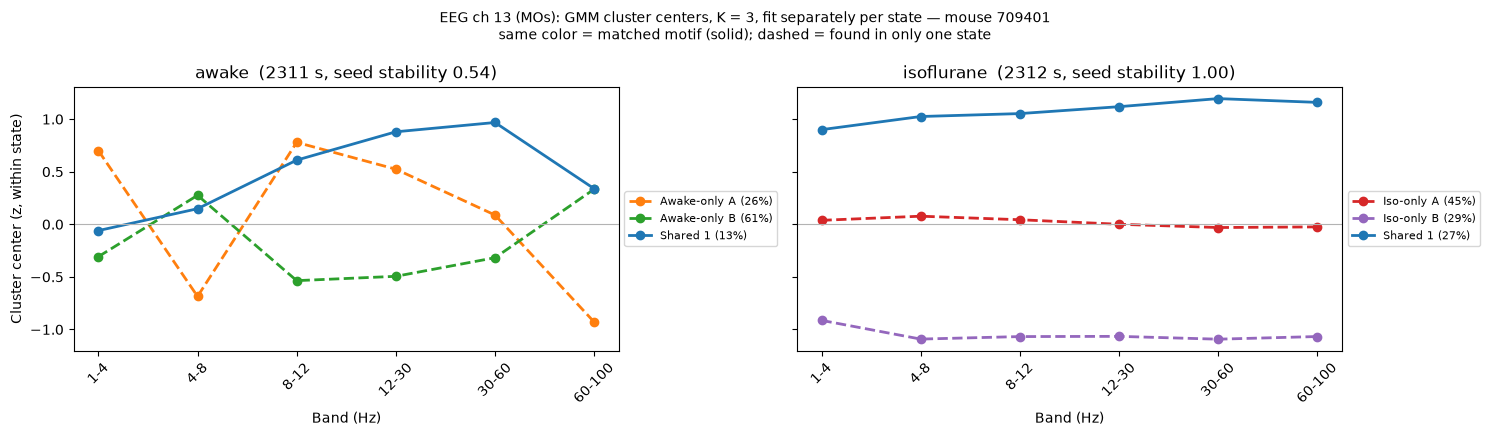

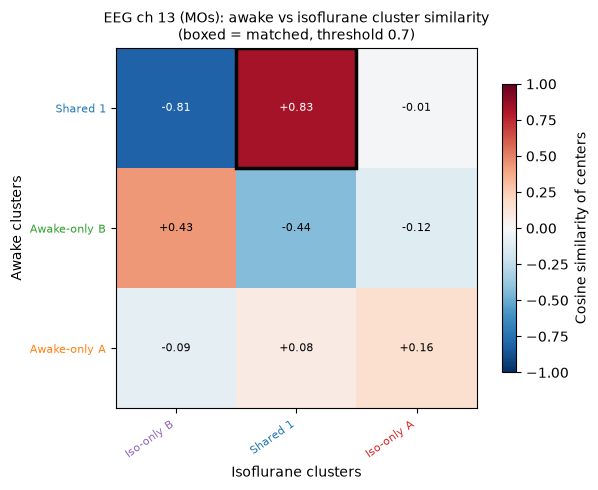

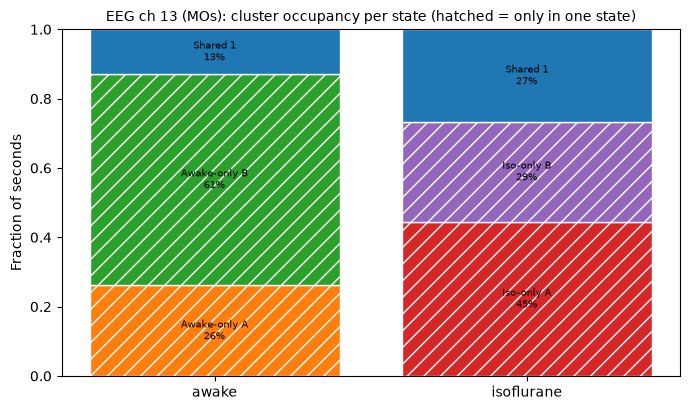

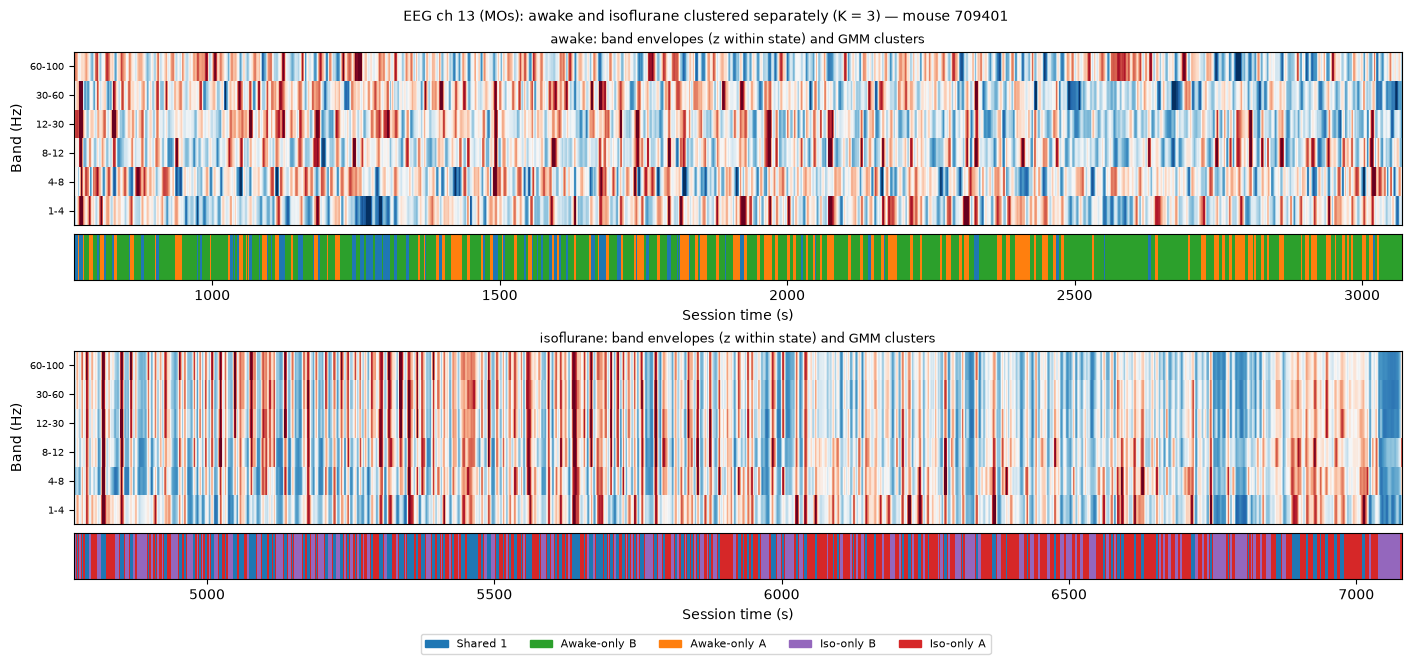

                         cluster  % of state linked to  best link cosine   1-4   4-8  8-12  12-30  30-60  60-100
name         state                                                                                              
Awake-only A awake             2        26.2         -               NaN  0.70 -0.69  0.78   0.52   0.09   -0.93
Awake-only B awake             1        61.0         -               NaN -0.31  0.28 -0.54  -0.49  -0.32    0.33
Iso-only A   isoflurane        2        44.6         -               NaN  0.04  0.08  0.04   0.00  -0.03   -0.02
Iso-only B   isoflurane        0        28.8         -               NaN -0.91 -1.09 -1.07  -1.07  -1.09   -1.07
Shared 1     awake             0        12.8  Shared 1              0.83 -0.06  0.15  0.61   0.88   0.97    0.34
             isoflurane        1        26.6  Shared 1              0.83  0.90  1.02  1.05   1.12   1.20    1.16


In [12]:
# === Same analysis at K = 3 (K = 5 results are kept; figures go to their own folder) ===
K_NEW = 3
saved = {"K": K, "fits": fits, "matches": matches, "OUT": OUT}
use_families = globals().get("MATCHING") == "families"

K = K_NEW
OUT = Path(f"results/709401_jahan/awake_vs_iso_gmm_K{K}")
OUT.mkdir(parents=True, exist_ok=True)

fits = {}
for name, sig in signals.items():
    for state in STATE_NAMES:
        d = split_state(sig, state)
        g = fit(d["X"], K)
        d["labels"] = g.predict(d["X"])
        d["centers"] = g.means_
        d["occupancy"] = np.bincount(d["labels"], minlength=K) / len(d["labels"])
        d["bic"] = saved["fits"][(name, state)]["bic"]          # BIC curve doesn't depend on K
        seed_labels = [fit(d["X"], K, seed=s, n_init=1).predict(d["X"]) for s in range(N_SEEDS)]
        d["stability"] = np.mean([adjusted_rand_score(a, b) for a, b in combinations(seed_labels, 2)])
        fits[(name, state)] = d

print(f"Seed stability (ARI), K = {saved['K']} vs K = {K}:")
for name in signals:
    for state in STATE_NAMES:
        print(f"  {name:16s} {state:10s}: {saved['fits'][(name, state)]['stability']:.2f} -> "
              f"{fits[(name, state)]['stability']:.2f}")

matches = {name: (match_families(name) if use_families else match_states(name)) for name in signals}
print(f"\nMatching: {'families' if use_families else 'one-to-one'}, threshold {SIMILAR}")
for name, (S, links, style) in matches.items():
    print(f"\n{name}: {len(links)} awake–isoflurane links")
    for a, i in links:
        print(f"  {style['awake'][a][0]:12s} (awake {a}) <-> {style['isoflurane'][i][0]:12s} (iso {i})  cosine {S[a, i]:+.2f}")

for name in signals:
    print(f"\n######## {name}, K = {K} ########")
    show_signal(name)

# Keep the K = 3 results under their own names, and put the K = 5 ones back
fits_K3, matches_K3 = fits, matches
K, fits, matches, OUT = saved["K"], saved["fits"], saved["matches"], saved["OUT"]